# **Data Visualisation**

## Objectives

* Answer BR3: turn the findings from notebook 03 into a small set of charts a
  non-technical reader can act on.
* Save each figure to `outputs/figures/` for use in the README and any
  presentation.

## Inputs

* `outputs/datasets/cleaned/bank_churners_cleaned.csv`
* `outputs/reports/variable_ranking.csv`

## Outputs

* Six figures in `outputs/figures/`.

## Design rules followed here

The retention team reads these, not analysts, so a few rules are applied
consistently rather than chart by chart:

* **One message per figure.** Each chart has a title that states the finding, not
  the variable names.
* **Rates, never counts.** The file is 5:1 imbalanced, so a count chart would
  describe the sample rather than the behaviour.
* **Group sizes sit under every bar**, as part of the axis label rather than
  floating text, so no reader takes the 100%-churn bar at face value without
  seeing it is 54 people.
* **Two colours only**, assigned by identity and used consistently. The pair was
  checked for colour-blind separation before use rather than picked by eye.
* **Nothing is encoded by colour alone** - every chart carries direct labels or a
  legend as well.

---

# Change working directory

In [1]:
import os
current_dir = os.getcwd()
current_dir

'G:\\Projects\\Credit_Card_Churn-Analysis-main\\Credit_Card_Churn-Analysis-main\\jupyter_notebooks'

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


In [3]:
current_dir = os.getcwd()
current_dir

'G:\\Projects\\Credit_Card_Churn-Analysis-main\\Credit_Card_Churn-Analysis-main'

---

# Section 1: Setup and house style

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch

df = pd.read_csv('outputs/datasets/cleaned/bank_churners_cleaned.csv')
ranking = pd.read_csv('outputs/reports/variable_ranking.csv')

os.makedirs('outputs/figures', exist_ok=True)

print(f"{df.shape[0]:,} customers loaded")

10,127 customers loaded


The two series colours are the first two slots of a categorical palette that
was validated for colour-blind separation (worst-pair difference well clear of
the threshold in normal, protan and tritan vision) and for contrast against the
chart background.

Orange marks the group or region under concern and blue the comparison, applied
consistently across all six figures. Neither colour is a red or a green, which
keeps the charts readable for the most common forms of colour blindness and
avoids implying a judgement about individual customers.

In [5]:
CONCERN  = '#eb6834'   # categorical slot 2 - orange
STEADY   = '#2a78d6'   # categorical slot 1 - blue
INK      = '#0b0b0b'   # primary text
INK_SOFT = '#52514e'   # secondary text
SURFACE  = '#fcfcfb'
GRID     = '#e2e1dd'

plt.rcParams.update({
    'figure.facecolor':  SURFACE,
    'axes.facecolor':    SURFACE,
    'savefig.facecolor': SURFACE,
    'axes.edgecolor':    GRID,
    'axes.labelcolor':   INK_SOFT,
    'axes.titlesize':    13,
    'axes.titleweight':  'bold',
    'axes.titlecolor':   INK,
    'text.color':        INK,
    'xtick.color':       INK_SOFT,
    'ytick.color':       INK_SOFT,
    'font.size':         10,
    'figure.dpi':        110,
    'savefig.dpi':       160,
    'savefig.bbox':      'tight',
})


def tidy(ax):
    """Strip chart junk: no top/right/left spines, recessive grid behind marks."""
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(GRID)
    ax.set_axisbelow(True)
    return ax


def label_bars(ax, bars, values, fmt="{:.0f}%", pad=1.2):
    """Put the value directly on each bar - never make the reader use the axis."""
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + pad, fmt.format(value),
                ha='center', va='bottom', fontsize=10,
                fontweight='bold', color=INK)


def ticks_with_n(labels, sizes):
    """Fold the group size into the tick label so the two can never collide."""
    return [f"{label}\nn={size:,}" for label, size in zip(labels, sizes)]


def save(fig, name):
    path = f'outputs/figures/{name}.png'
    fig.savefig(path)
    print(f"saved {path}")

---

# Figure 1: The size of the problem (BR1)

This one is deliberately not a chart. A single proportion is a number, and a
pie chart of two slices makes the reader do work to recover a figure that can
simply be stated. A proportional strip is included underneath so the share is
seen as well as read.

saved outputs/figures/01_churn_overview.png


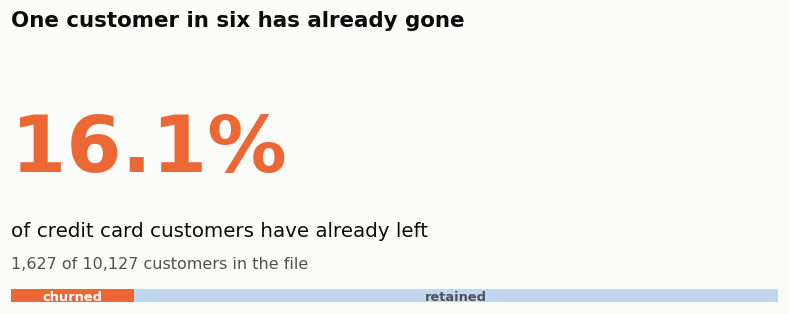

In [6]:
churn_rate = df['Churn'].mean()
n_churned = int(df['Churn'].sum())
n_total = len(df)

fig, ax = plt.subplots(figsize=(9, 3))
ax.axis('off')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.text(0, 0.60, f"{churn_rate:.1%}", fontsize=52, fontweight='bold',
        color=CONCERN, va='center', ha='left')
ax.text(0, 0.28, "of credit card customers have already left",
        fontsize=13, color=INK, va='center', ha='left')
ax.text(0, 0.15, f"{n_churned:,} of {n_total:,} customers in the file",
        fontsize=10.5, color=INK_SOFT, va='center', ha='left')

ax.barh([0.02], [1.0], height=0.06, color=STEADY, alpha=0.28)
ax.barh([0.02], [churn_rate], height=0.06, color=CONCERN)
ax.text(churn_rate / 2, 0.02, "churned", fontsize=8.5, color='white',
        va='center', ha='center', fontweight='bold')
ax.text(churn_rate + (1 - churn_rate) / 2, 0.02, "retained", fontsize=8.5,
        color=INK_SOFT, va='center', ha='center', fontweight='bold')

ax.set_title("One customer in six has already gone", loc='left',
             pad=14, fontsize=14)

save(fig, '01_churn_overview')
plt.show()

**Read:** 1,627 of 10,127 customers have churned. The imbalance shown in the
strip is why every chart below reports rates rather than counts.

---

# Figure 2: Card activity (H1)

Notebook 03 found transaction count to be the single strongest
discriminator - a median of 43 transactions for churned customers against 71 for
retained ones.

The rate-by-band table is printed first, because it carries the threshold
finding. The figure then shows the two **distributions** directly, which is the
honest form for this variable: churn rate by band is not a clean slope (it peaks
mid-range), whereas the distributions show plainly that the two groups sit in
different places.

In [7]:
bands = pd.cut(df['Total_Trans_Ct'],
               bins=[0, 30, 40, 50, 60, 70, 80, 200],
               labels=['1-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81+'])

by_band = df.groupby(bands, observed=True)['Churn'].agg(['size', 'mean'])
by_band.columns = ['customers', 'churn_rate']
by_band['churn_rate_pct'] = (by_band['churn_rate'] * 100).round(1)
by_band[['customers', 'churn_rate_pct']]

,customers,churn_rate_pct
Total_Trans_Ct,,
1-30,698,29.2
31-40,1240,32.8
41-50,1190,48.4
51-60,919,22.2
61-70,1641,7.6
71-80,1889,4.2
81+,2550,1.2


Above 60 transactions a year churn drops to 8%, then 4%, then 1%. Below 60
it runs between 22% and 48% - elevated, but **not** ordered. It peaks at 48% in
the 41-50 band and is lower at both ends, because churned customers cluster
around a median of 43 and the lowest band holds only 698 people.

So the threshold is the finding; the ranking of the bands below it is not.

saved outputs/figures/02_transaction_count_distribution.png


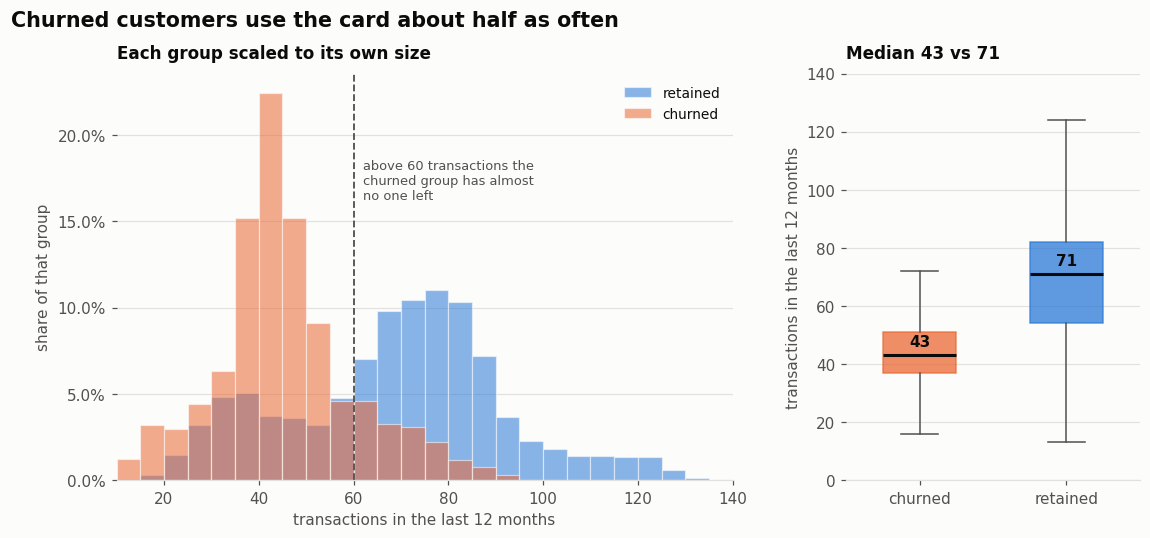

In [8]:
churned = df.loc[df['Churn'] == 1, 'Total_Trans_Ct']
retained = df.loc[df['Churn'] == 0, 'Total_Trans_Ct']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8),
                         gridspec_kw={'width_ratios': [2.1, 1]})
fig.subplots_adjust(wspace=0.25)

# --- Left: histogram of each group, scaled to its own size -------------------
ax = axes[0]
bin_edges = np.arange(10, 145, 5)

for values, colour, label in [(retained, STEADY, 'retained'),
                              (churned, CONCERN, 'churned')]:
    ax.hist(values, bins=bin_edges, color=colour, alpha=0.55,
            weights=np.ones(len(values)) / len(values) * 100,
            label=label, edgecolor=SURFACE, linewidth=0.8)

ax.axvline(60, color=INK_SOFT, linewidth=1.2, linestyle='--')
ax.text(62, 18.6, 'above 60 transactions the\nchurned group has almost\nno one left',
        fontsize=8.5, color=INK_SOFT, va='top')

ax.set_xlabel('transactions in the last 12 months')
ax.set_ylabel('share of that group')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_xlim(10, 140)
ax.grid(axis='y', color=GRID, linewidth=0.8)
ax.legend(frameon=False, fontsize=9, loc='upper right')
ax.set_title('Each group scaled to its own size', loc='left',
             fontsize=11, pad=10)
tidy(ax)

# --- Right: box plot, the same variable summarised --------------------------
ax = axes[1]
box = ax.boxplot([churned, retained], patch_artist=True, widths=0.5,
                 labels=['churned', 'retained'], showfliers=False,
                 medianprops=dict(color=INK, linewidth=2))
for patch, colour in zip(box['boxes'], [CONCERN, STEADY]):
    patch.set_facecolor(colour)
    patch.set_alpha(0.75)
    patch.set_edgecolor(colour)
for element in ['whiskers', 'caps']:
    for item in box[element]:
        item.set_color(INK_SOFT)

for position, values in [(1, churned), (2, retained)]:
    ax.text(position, values.median() + 3, f"{values.median():.0f}",
            ha='center', fontsize=10, fontweight='bold', color=INK)

ax.set_ylabel('transactions in the last 12 months')
ax.set_ylim(0, 140)
ax.grid(axis='y', color=GRID, linewidth=0.8)
ax.set_title('Median 43 vs 71', loc='left', fontsize=11, pad=10)
tidy(ax)

fig.suptitle("Churned customers use the card about half as often",
             fontsize=13.5, fontweight='bold', x=0.045, ha='left', y=1.0)

save(fig, '02_transaction_count_distribution')
plt.show()

**Read:** the histogram scales each group to its own size, so the shapes can
be compared despite the 5:1 imbalance. The churned group is concentrated between
roughly 30 and 55 transactions and has almost nobody above 60; the retained group
is centred around 70-80 with a long tail upward. The box plot summarises the same
thing - medians of 43 and 71, with the boxes barely overlapping.

Whiskers are drawn without outlier points, since 10,127 individual markers would
obscure the summary the box plot exists to give.

# Figure 3: Products held, and the cliff between two and three (H2)

saved outputs/figures/03_churn_by_products_held.png


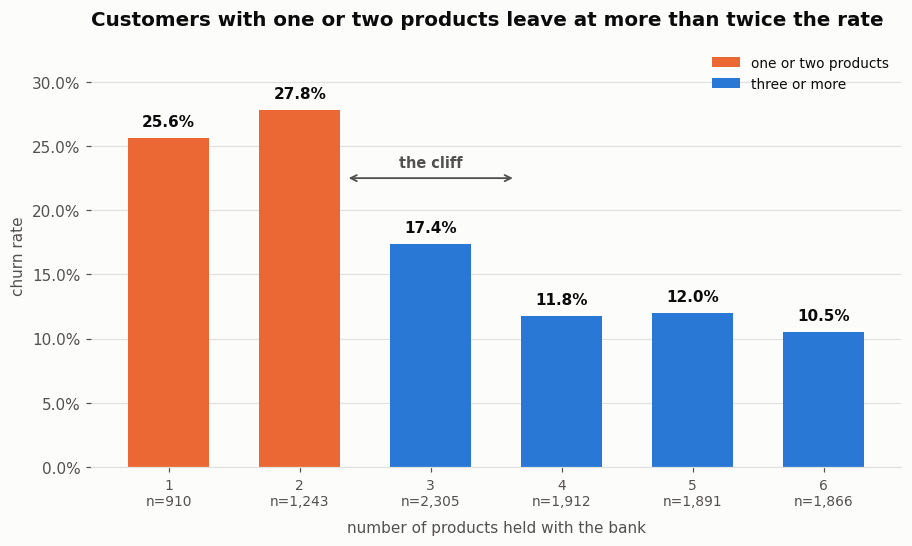

In [9]:
by_products = df.groupby('Total_Relationship_Count', observed=True)['Churn'].agg(['mean', 'size'])
by_products['pct'] = by_products['mean'] * 100

fig, ax = plt.subplots(figsize=(9.5, 5))

colours = [CONCERN if idx <= 2 else STEADY for idx in by_products.index]
positions = np.arange(len(by_products))
bars = ax.bar(positions, by_products['pct'], color=colours, width=0.62)
label_bars(ax, bars, by_products['pct'].values, fmt="{:.1f}%", pad=0.7)

ax.set_xticks(positions)
ax.set_xticklabels(ticks_with_n(by_products.index.astype(str), by_products['size']),
                   fontsize=9)

ax.annotate('', xy=(1.35, 22.5), xytext=(2.65, 22.5),
            arrowprops=dict(arrowstyle='<->', color=INK_SOFT, linewidth=1.2))
ax.text(2.0, 23.4, 'the cliff', fontsize=9.5, color=INK_SOFT,
        ha='center', fontweight='bold')

ax.set_ylabel('churn rate')
ax.set_xlabel('number of products held with the bank', labelpad=8)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, 33)
ax.grid(axis='y', color=GRID, linewidth=0.8)
ax.set_title("Customers with one or two products leave at more than twice the rate",
             loc='left', pad=12)
ax.legend(handles=[Patch(facecolor=CONCERN, label='one or two products'),
                   Patch(facecolor=STEADY, label='three or more')],
          frameon=False, loc='upper right', fontsize=9)
tidy(ax)

save(fig, '03_churn_by_products_held')
plt.show()

**Read:** churn runs at 25.6% and 27.8% for customers holding one or two
products, then falls to 17.4% at three and 10-12% from four upwards. The change
happens between two products and three, not gradually across the range - so the
retention goal for a one- or two-product customer is a third product, and pushing
an existing four-product customer to five buys very little.

---

# Figure 4: Contact frequency (H4)

This is the steepest gradient in the data and also the one most likely to be
misread, so the chart carries its own caveat.

saved outputs/figures/04_churn_by_contact_count.png


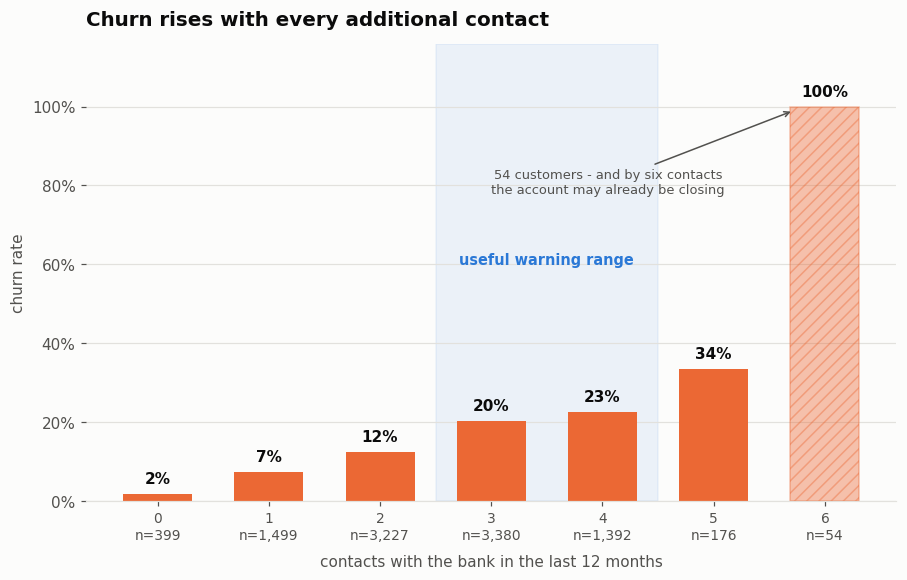

In [10]:
by_contacts = df.groupby('Contacts_Count_12_mon', observed=True)['Churn'].agg(['mean', 'size'])
by_contacts['pct'] = by_contacts['mean'] * 100

fig, ax = plt.subplots(figsize=(9.5, 5.4))

positions = np.arange(len(by_contacts))
bars = ax.bar(positions, by_contacts['pct'], color=CONCERN, width=0.62)

# The final bar is a 54-customer threshold effect, not a behavioural law.
bars[-1].set_alpha(0.40)
bars[-1].set_hatch('///')
bars[-1].set_edgecolor(CONCERN)

label_bars(ax, bars, by_contacts['pct'].values, pad=2.0)

ax.set_xticks(positions)
ax.set_xticklabels(ticks_with_n(by_contacts.index.astype(str), by_contacts['size']),
                   fontsize=9)

ax.axvspan(2.5, 4.5, color=STEADY, alpha=0.08, zorder=0)
ax.text(3.5, 60, 'useful warning range', fontsize=9.5, color=STEADY,
        ha='center', fontweight='bold')

ax.annotate('54 customers - and by six contacts\nthe account may already be closing',
            xy=(5.72, 99), xytext=(4.05, 78),
            fontsize=8.5, color=INK_SOFT, ha='center',
            arrowprops=dict(arrowstyle='->', color=INK_SOFT, linewidth=1))

ax.set_ylabel('churn rate')
ax.set_xlabel('contacts with the bank in the last 12 months', labelpad=8)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, 116)
ax.grid(axis='y', color=GRID, linewidth=0.8)
ax.set_title("Churn rises with every additional contact", loc='left', pad=12)
tidy(ax)

save(fig, '04_churn_by_contact_count')
plt.show()

**Read:** churn climbs at every step, from 1.8% at no contacts to 33.5% at
five. The hatched final bar - 100% of 54 customers - is drawn differently on
purpose. A rate of exactly 100% on a clean threshold usually means the measure
has caught the closing process rather than a warning of it, and acting at six
contacts would in any case be too late. The shaded band marks where the signal is
both steep and still actionable.

---

# Figure 5: Behaviour beats demography (H5)

The commercially important result, and the one that decides where the
retention team should look. Each variable is scored by how far knowing it moves
the churn rate.

saved outputs/figures/05_behaviour_vs_demography.png


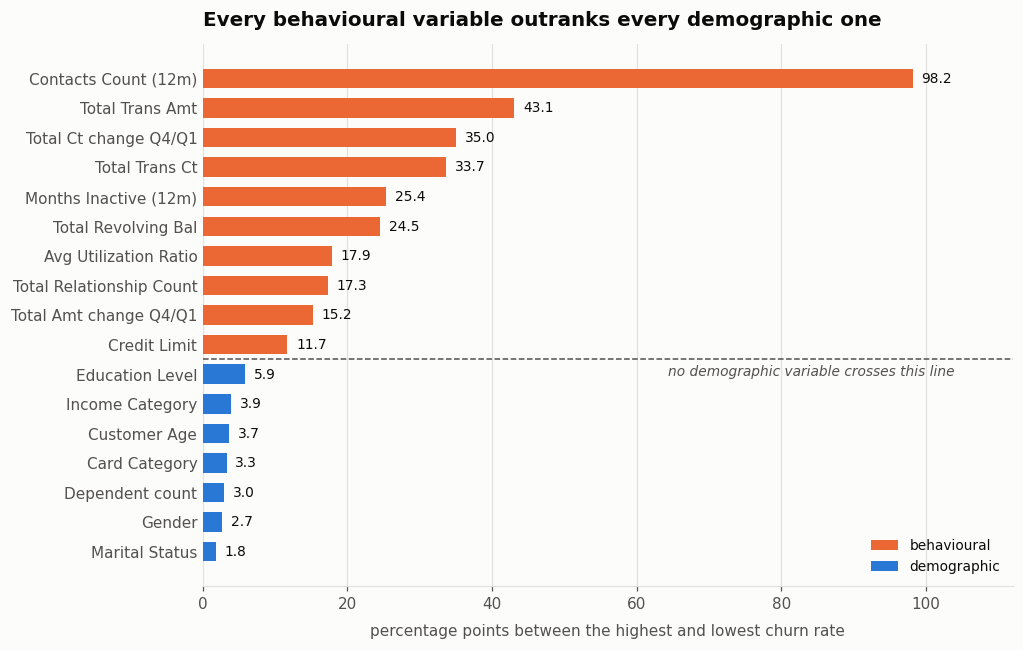

In [11]:
rank = ranking.sort_values('spread_pp')
labels = (rank['variable'].str.replace('_', ' ')
                          .str.replace('12 mon', '(12m)')
                          .str.replace('Chng Q4 Q1', 'change Q4/Q1'))
colours = [CONCERN if t == 'behavioural' else STEADY for t in rank['type']]

fig, ax = plt.subplots(figsize=(9.5, 6.4))
bars = ax.barh(labels, rank['spread_pp'], color=colours, height=0.66)

for bar, value in zip(bars, rank['spread_pp']):
    ax.text(value + 1.2, bar.get_y() + bar.get_height() / 2, f"{value:.1f}",
            va='center', ha='left', fontsize=9, color=INK)

boundary = (rank['type'].values == 'behavioural').argmax()
ax.axhline(boundary - 0.5, color=INK_SOFT, linewidth=1, linestyle='--')
ax.text(104, boundary - 1.05, 'no demographic variable crosses this line',
        fontsize=9, color=INK_SOFT, ha='right', style='italic')

ax.set_xlabel('percentage points between the highest and lowest churn rate',
              labelpad=8)
ax.set_xlim(0, 112)
ax.grid(axis='x', color=GRID, linewidth=0.8)
ax.set_title("Every behavioural variable outranks every demographic one",
             loc='left', pad=12)
ax.legend(handles=[Patch(facecolor=CONCERN, label='behavioural'),
                   Patch(facecolor=STEADY, label='demographic')],
          frameon=False, loc='lower right', fontsize=9)
tidy(ax)
ax.tick_params(axis='y', length=0)

save(fig, '05_behaviour_vs_demography')
plt.show()

**Read:** the separation is complete - there is no overlap between the two
groups. The weakest behavioural variable moves the churn rate twice as far as the
strongest demographic one. Marital status shifts it by 1.8 percentage points;
contact count by 98.

The practical conclusion is that retention triggers should be built from account
activity. That is also the defensible choice. Gender and age are protected
characteristics under the Equality Act 2010; income, education and marital status
are not, but they are sensitive demographic attributes that can act as proxies
for protected ones. Targeting retention offers on any of them would carry
discrimination risk in exchange for almost no predictive value.

---

# Figure 6: The dormant balance, and why it needs a second variable

The finding none of the hypotheses anticipated. A scatter is the right form
here because the point is precisely that **one variable is not enough** - the
message lives in the combination of two, which a bar chart cannot show.

In [12]:
df['zero_balance'] = (df['Total_Revolving_Bal'] == 0)

zero_only = df[df['zero_balance']]
quiet = zero_only[zero_only['Total_Trans_Ct'] < 60]
active = zero_only[zero_only['Total_Trans_Ct'] >= 60]

share = df.groupby('Attrition_Flag')['zero_balance'].mean().mul(100).round(1)
print(f"Carrying a zero balance - churned {share['Attrited Customer']}%, "
      f"retained {share['Existing Customer']}%")
print(f"Zero balance AND under 60 transactions: {len(quiet):,} customers, "
      f"churn {quiet['Churn'].mean():.1%}")
print(f"Zero balance AND 60+ transactions:      {len(active):,} customers, "
      f"churn {active['Churn'].mean():.1%}")

Carrying a zero balance - churned 54.9%, retained 18.6%
Zero balance AND under 60 transactions: 1,108 customers, churn 68.0%
Zero balance AND 60+ transactions:      1,362 customers, churn 10.3%


saved outputs/figures/06_zero_balance_needs_activity.png


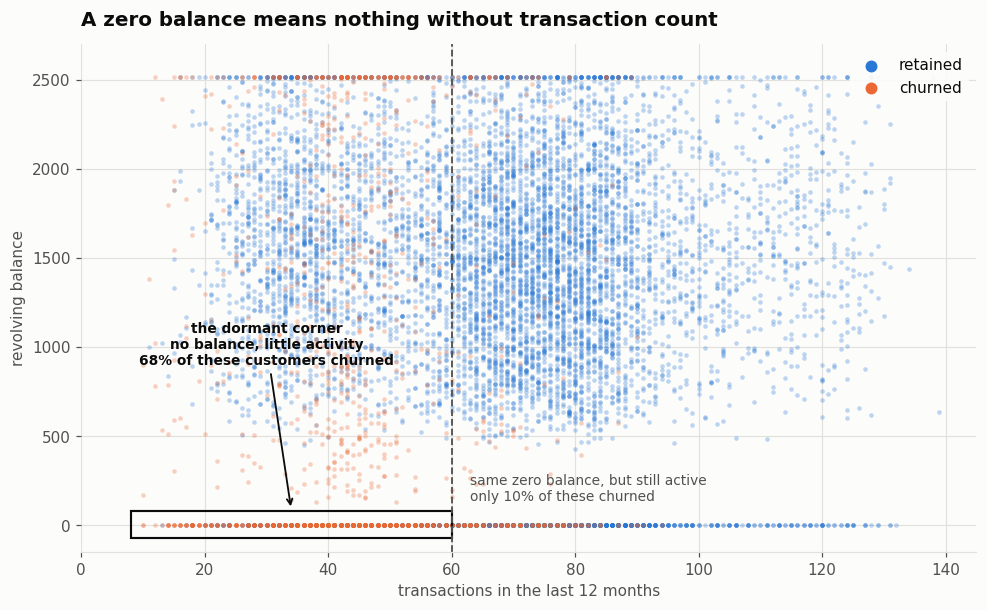

In [13]:
fig, ax = plt.subplots(figsize=(10.5, 6))

# Retained first so the smaller churned group stays visible on top.
for mask, colour, label in [(df['Churn'] == 0, STEADY, 'retained'),
                            (df['Churn'] == 1, CONCERN, 'churned')]:
    ax.scatter(df.loc[mask, 'Total_Trans_Ct'],
               df.loc[mask, 'Total_Revolving_Bal'],
               s=9, alpha=0.30, color=colour, label=label, linewidths=0)

ax.axvline(60, color=INK_SOFT, linewidth=1.2, linestyle='--')

# The dormant corner: no balance and little activity.
ax.add_patch(plt.Rectangle((8, -70), 52, 150, fill=False,
                           edgecolor=INK, linewidth=1.4, linestyle='-'))
ax.annotate('the dormant corner\nno balance, little activity\n68% of these customers churned',
            xy=(34, 90), xytext=(30, 900),
            fontsize=9, color=INK, ha='center', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=INK, linewidth=1.2))

ax.text(63, 120, 'same zero balance, but still active\nonly 10% of these churned',
        fontsize=9, color=INK_SOFT, va='bottom')

legend = ax.legend(loc='upper right', fontsize=10, markerscale=2.6,
                   frameon=True, facecolor=SURFACE, edgecolor='none',
                   framealpha=0.92)
for handle in legend.legend_handles:
    handle.set_alpha(1)

ax.set_xlabel('transactions in the last 12 months')
ax.set_ylabel('revolving balance')
ax.set_xlim(0, 145)
ax.set_ylim(-150, 2700)
ax.grid(color=GRID, linewidth=0.8)
ax.set_title("A zero balance means nothing without transaction count",
             loc='left', pad=12)
tidy(ax)

save(fig, '06_zero_balance_needs_activity')
plt.show()

**Read:** the dense band along the bottom is every customer carrying no
revolving balance - 54.9% of churned customers against 18.6% of retained. On its
own that band looks like a churn signal.

It is not, and the horizontal axis is why. Split that same band at 60
transactions and it comes apart: customers in the boxed corner - no balance and
little activity - churn at **68.0%** (n = 1,108), while zero-balance customers
still transacting freely churn at **10.3%** (n = 1,362).

A zero balance describes two opposite customers: one who pays in full every
month, and one who has stopped using the card. Only transaction count tells them
apart, and a campaign aimed at the whole bottom band would spend most of its
budget on people who are simply paying their bills.

Points are drawn small and semi-transparent because 10,127 opaque markers would
hide the density that carries the finding.

# Conclusions and Next Steps

Six figures saved to `outputs/figures/`, each answering one question:

| Figure | Finding |
|---|---|
| 01 | 16.07% of customers have churned - 1,627 of 10,127 |
| 02 | Churned customers transact about half as often - median 43 vs 71 |
| 03 | The cliff sits between two products and three |
| 04 | Churn rises with every contact; useful as a flag at 3-5 |
| 05 | Every behavioural variable outranks every demographic one |
| 06 | A zero balance is only meaningful alongside transaction count |

**BR3 is answered.** Each chart states its finding in its title, carries group
sizes on the axis so no reader over-trusts a thin bar, and shows its caveat where
it has one.

**Plot types used.** Bar (figures 3 and 4), horizontal bar (figures 1 and 5),
histogram and box plot (figure 2), and scatter (figure 6). The form was chosen
per figure from what the data had to say: counts of a discrete variable suit
bars, a distribution comparison suits a histogram, and a finding that only holds
for two variables together needs a scatter.

**One chart changed twice.** Figure 2 was first built as a bar chart of churn
rate by activity band, titled as a steady decline. The rendered chart disproved
it - the rate peaks mid-range rather than at the bottom - so it was rewritten
around the threshold. It was then changed again to a histogram and box plot,
because comparing the two distributions is the honest form for a variable whose
rate-by-band is not monotonic. The rate table is still printed above the figure,
since that is what carries the threshold number.

**A limitation of the medium.** These are static images. In an interactive report
each chart would carry hover detail with exact figures; here that information is
placed directly on the bars instead, which is why every bar is labelled rather
than leaving the reader to estimate against the axis.

The findings and recommendations are written up in the README.